**Initialization, unzipping of data,  supporting functions**


In [4]:
import sys; sys.path.insert(0, "."); sys.path.insert(1, "..") 
import ast
import matplotlib.pyplot as plt
import os
import train

# unzip data files (run only once)
if not os.path.isfile('../data/4.train'): 
    print("unzipping")
    !ls ../data/*
    !gunzip -k ../data/*




**Training the model for one epoch (5 loop)**

In [9]:
# you can change model parameters here, the rest are the default
my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.test', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 1,
        'batch_size_eval':1000,
         'n_enc_layers':2,
         'n_dec_layers':2,
         'enc_emb_dim':128,
         'dec_emb_dim':128,
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)




INFO - 11/16/26 13:25:39 - 0:01:04 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/16/26 13:25:39 - 0:00:00 - ============ Initialized logger ============
INFO - 11/16/26 13:25:39 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 32
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-a9bf4a05-06d4-4735-843e-755a8ca29e7f.json --exp_id 2026_11_16_13_25_

**Logs and model save files,  Loss curve of the previous trained model**

In [34]:
# support functions (read the files, param is the train.log file path)
def read_losses(filename):
    res = []
    with open(filename, 'rt') as f:
        for line in f:
            if line.find("- LOSS") >=0:
                res.append(float(line.split(' ')[-4]))
    return res

def read_logs(filename):
    logs=[]
    with open(filename, 'rt') as f:
        for line in f:
            pos = line.find('__log__:')
            if pos >=0:
                dic = ast.literal_eval(line[pos+8:])
                logs.append(dic)
    return logs

def draw_train_loss(file,graph):
    loss = read_losses(file)

    graph.plot(loss,linewidth=1)
    if hasattr(graph, "set_title"):
        graph.set_title("training loss")
    else:
        graph.title("training loss")
    
def draw_test_loss(file,graph):
    indicators = ["xe_loss"]
    prefix = "valid_AMPLITUDE_"
    perf = read_logs(file)
    v1 = [p[prefix+'xe_loss'] for p in perf]
    graph.plot(v1,linewidth=1,label="Accuracy")
    if hasattr(graph, "set_title"):
        graph.set_title("Test loss")
    else:
        graph.title("Test loss")
    
def draw_accuracy(file,graph):
    indicators = ["avg_correct_sign","avg_correct_module"]
    prefix = "valid_AMPLITUDE_"
    perf = read_logs(file)

    v1 = [p[prefix+"acc"]/100.0 for p in perf]

    graph.plot(v1,linewidth=1,label="Accuracy")
    for i in indicators:
        v = [p[prefix+i] for p in perf]
        graph.plot(v, linewidth=1, label=i)
    if hasattr(graph, "set_title"):
        graph.set_title("Accuracy")
    else:
        graph.title("Accuracy")
    graph.legend()
    


All results are dumped into debug/2026_11_16_14_34_01

total 16600
-rw-r--r--@ 1 francoischarton  staff  7502617 Nov 16 14:37 checkpoint.pth
-rw-r--r--@ 1 francoischarton  staff     1497 Nov 16 14:34 params.pkl
-rw-r--r--@ 1 francoischarton  staff    37961 Nov 16 14:37 train.log

checkpoint.pth constains the model weights
train.log the experiment log


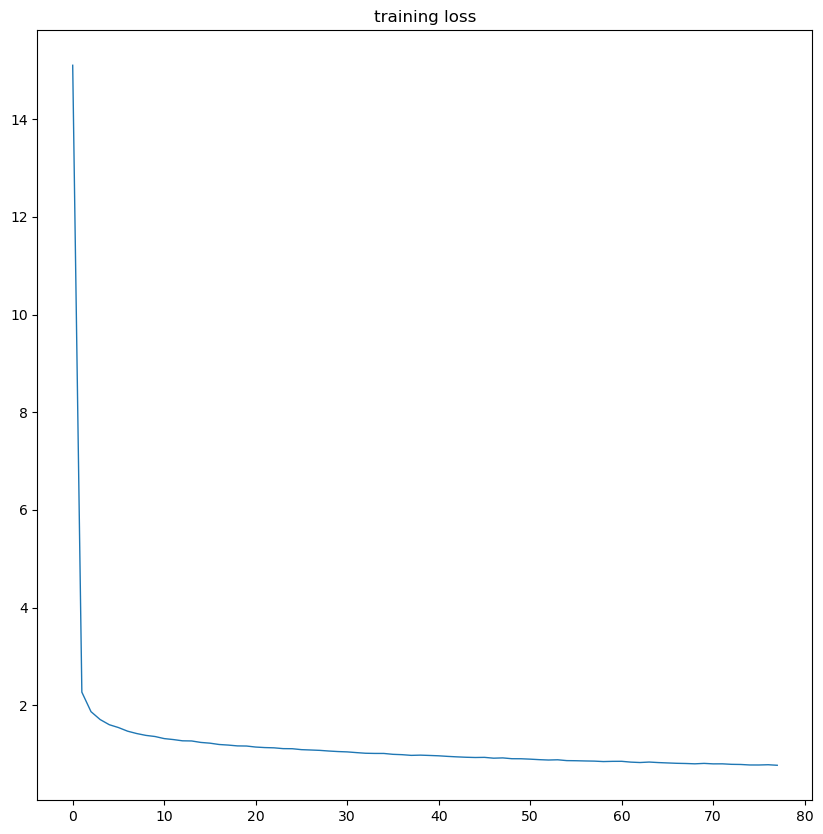

<class 'module'>

Final performances
epoch : 9
valid_AMPLITUDE_xe_loss : 0.7728089599250451
valid_AMPLITUDE_greedy_acc : 21.98
valid_AMPLITUDE_acc : 31.68
valid_AMPLITUDE_well_formed : 99.96
valid_AMPLITUDE_acc_-1 : 19.631147540983605
valid_AMPLITUDE_acc_1 : 43.1640625
valid_AMPLITUDE_avg_correct_sign : 0.6146
valid_AMPLITUDE_avg_correct_module : 0.4184


In [35]:



path = params.dump_path

print(f'All results are dumped into {path}')
print()
!ls -l {path}

print()
print("checkpoint.pth constains the model weights")
print("train.log the experiment log")

logfile = os.path.join(path,"train.log")

draw_train_loss(logfile,plt)
plt.rcParams['figure.figsize'] = [10,10]
plt.show()

last_perf = read_logs(logfile)[-1]
print()
print("Final performances")
for s in last_perf:
    print(s, ":" , last_perf[s])


**Data saved in /checkpoint (loop 6, unique coefficients, 39 epochs) loss curve**

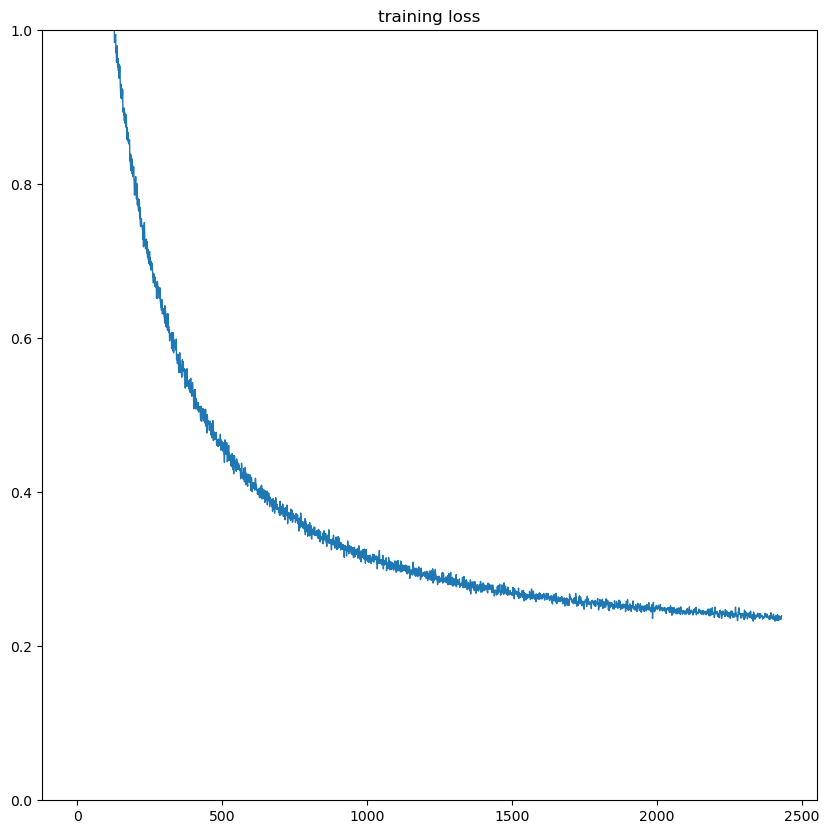

In [13]:
path = '../checkpoint/'

logfile = os.path.join(path,"train.log")

draw_train_loss(logfile, plt)

plt.ylim(0,1)
plt.rcParams['figure.figsize'] = [10,10]
plt.show()




**Accuracies/signs/modules**

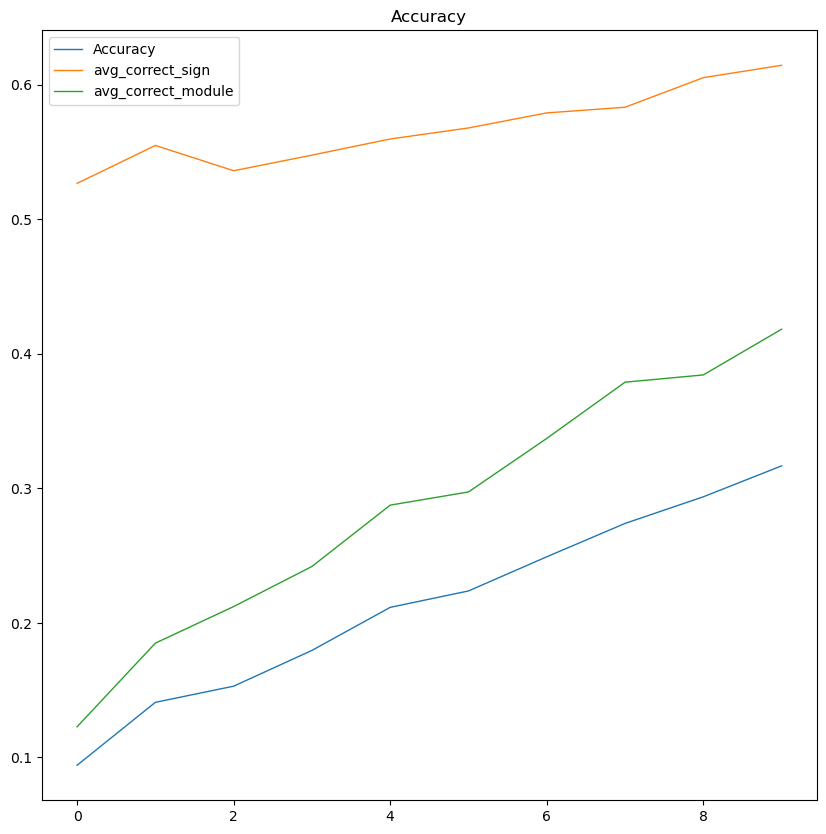

In [36]:

draw_accuracy(logfile, plt)

plt.rcParams['figure.figsize'] = [10,10]
plt.show()




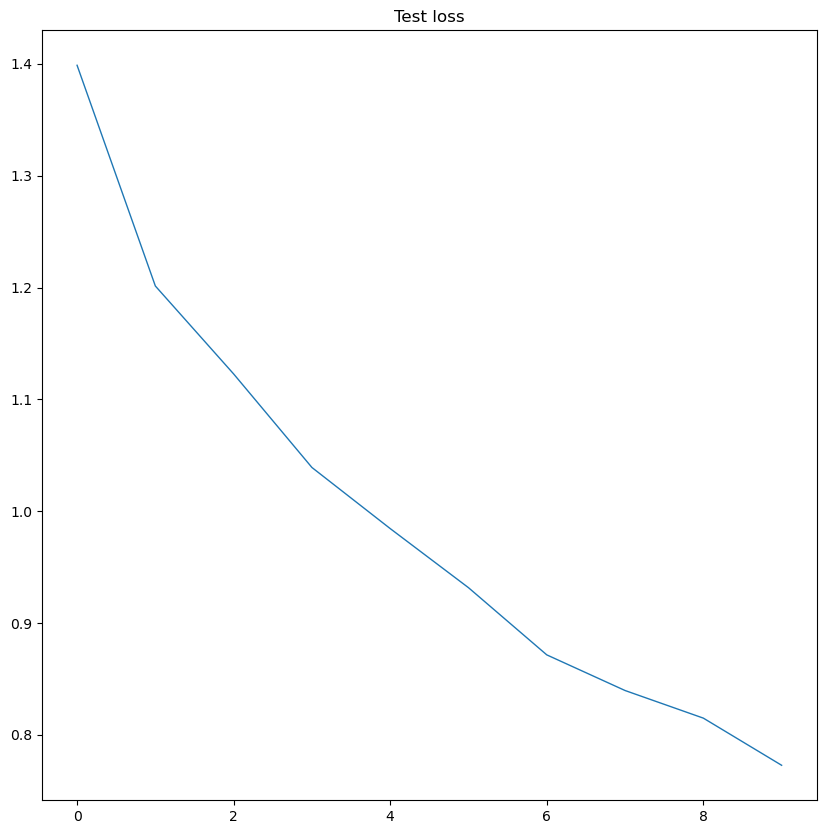

In [37]:
draw_test_loss(logfile, plt)

plt.rcParams['figure.figsize'] = [10,10]
plt.show()

**overfitting with small models (5 minutes to run)**

In [38]:
# you can change model parameters here, the rest are the default
# max_eamples 5k (12.5% of dataset) slight overfit, 10k slight (25%), 20k (50%) almost none 

my_params= {'reload_data':'amplitude:../data/5u.train',
         'eval_data':'../data/5u.test', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 15,
         'max_examples':5000,
        'batch_size_eval':1000,
        'batch_size':64,
        'n_enc_layers':1,
        'n_dec_layers':1,
         'enc_emb_dim':128,
         'dec_emb_dim':128,
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)




INFO - 11/16/26 15:33:19 - 0:59:19 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/16/26 15:33:19 - 0:00:00 - ============ Initialized logger ============
INFO - 11/16/26 15:33:19 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-a9bf4a05-06d4-4735-843e-755a8ca29e7f.json --exp_id 2026_11_16_15_33_

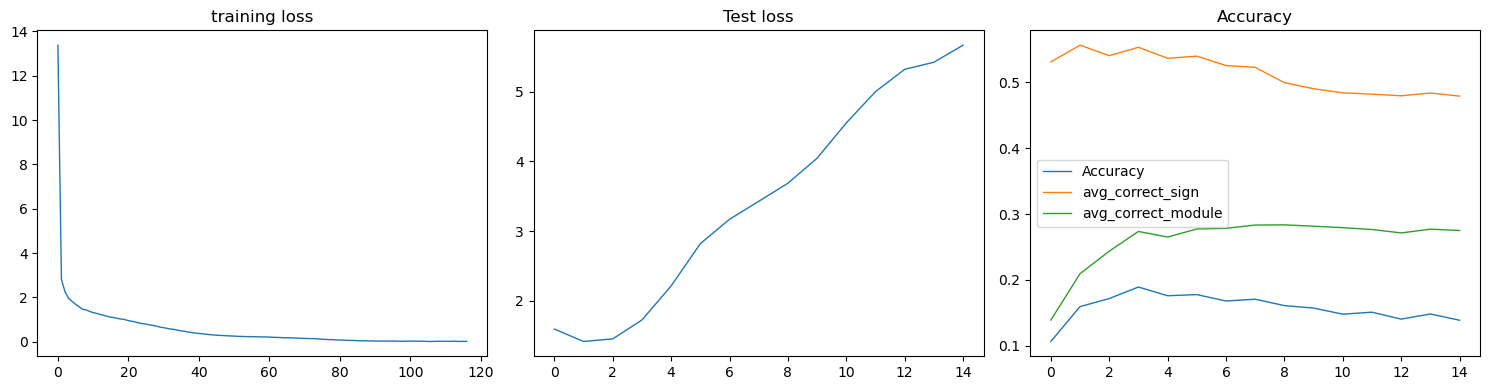

In [39]:
indicators = ["xe_loss"]
prefix = "valid_AMPLITUDE_"
logfile = os.path.join(params.dump_path,"train.log")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 ligne, 3 colonnes

draw_train_loss(logfile, axes[0])
draw_test_loss(logfile, axes[1])
draw_accuracy(logfile, axes[2])

plt.tight_layout()
plt.show()


In [23]:

# Varying LR 0.01 doesn't learn, 0.001 does
# can try adgrad, sgd

my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.valid', 
         'eval_size':-1,
         'epoch_size':100000,
         'max_epoch': 10,
         'max_examples':-1,
        'batch_size_eval':1000,
        'batch_size':64,
        'n_enc_layers':1,
        'n_dec_layers':1,
         'enc_emb_dim':128,
         'dec_emb_dim':128,
          'optimizer': "adam,lr=0.0001",
        'base': 101
         }


parser = train.get_parser()
params = parser.parse_args([])

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
    

# check parameters and run the model
train.check_model_params(params)
train.main(params)


INFO - 11/16/26 14:34:01 - 0:05:54 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/16/26 14:34:01 - 0:00:00 - ============ Initialized logger ============
INFO - 11/16/26 14:34:01 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 101
                                     batch_size: 64
                                     batch_size_eval: 1000
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-a9bf4a05-06d4-4735-843e-755a8ca29e7f.json --exp_id 2026_11_16_14_34_0

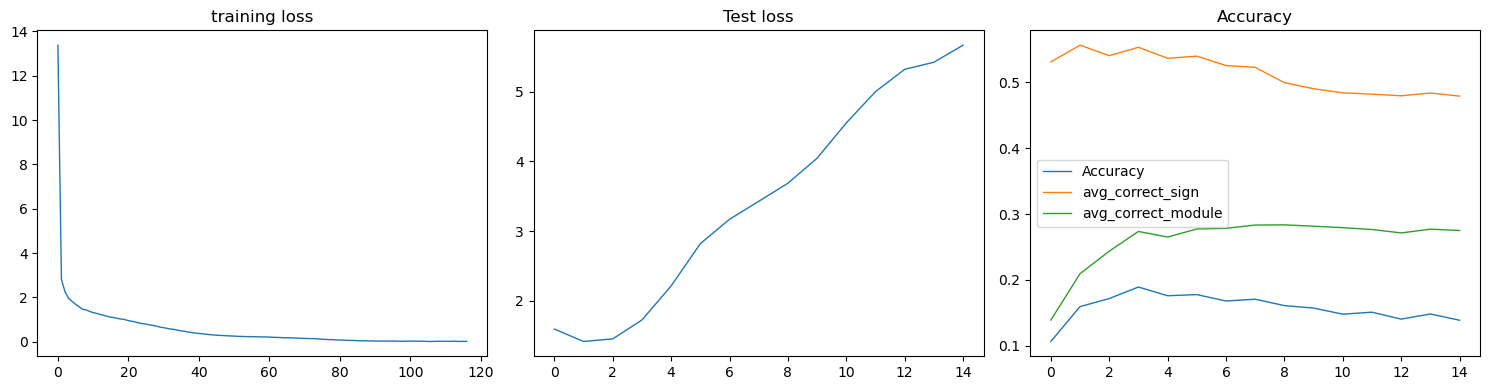

In [40]:
indicators = ["xe_loss"]
prefix = "valid_AMPLITUDE_"
logfile = os.path.join(params.dump_path,"train.log")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))   # 1 ligne, 3 colonnes

draw_train_loss(logfile, axes[0])
draw_test_loss(logfile, axes[1])
draw_accuracy(logfile, axes[2])

plt.tight_layout()
plt.show()


**Evaluating a checkpointed file**

In [62]:
import pickle
my_params= {'reload_data':'amplitude:../data/5.train',
         'eval_data':'../data/5.valid', 
         'eval_from_exp':'../checkpoint/', 
        'eval_only':'true'
         }


parser = train.get_parser()
params = parser.parse_args([])
# read params from pickle
pickle_file = my_params['eval_from_exp'] + "/params.pkl"
assert os.path.isfile(pickle_file)
with open(pickle_file, "rb") as f:
    pk = pickle.load(f)
pickled_args = pk.__dict__
del pickled_args["exp_id"]
pickled_args["eval_only"]="true"
for k, v in pickled_args.items():
    #if getattr(params, k, None) is None:
    setattr(params, k, v)

# update model params with the ones selected abov
for k,v in my_params.items():
    setattr(params,k,v)
params.reload_checkpoint = os.path.join(params.eval_from_exp,"checkpoint.pth")

# check parameters and run the model
train.check_model_params(params)
train.main(params)


INFO - 11/16/26 17:29:51 - 0:00:43 - Rank 0/1, local_rank=0, is_master=True
INFO - 11/16/26 17:29:51 - 0:00:00 - ============ Initialized logger ============
INFO - 11/16/26 17:29:51 - 0:00:00 - activation: gelu
                                     amp: False
                                     architecture: encoder_decoder
                                     attention_dropout: 0
                                     base: 1000
                                     batch_size: 32
                                     batch_size_eval: 128
                                     beam_eval: False
                                     beam_length_penalty: 1
                                     beam_size: 1
                                     clip_grad_norm: 5
                                     command: /opt/anaconda3/lib/python3.13/site-packages/ipykernel_launcher.py -f /Users/francoischarton/Library/Jupyter/runtime/kernel-a9bf4a05-06d4-4735-843e-755a8ca29e7f.json --exp_id 2026_11_16_17_29_5

NameError: name 'exit' is not defined